PARTEA C: Relații liniare și regresie liniară

În această parte analizăm două perechi de features pentru a vedea dacă există o relație liniară între ele. Pentru fiecare pereche calculăm coeficientul de corelație Pearson și folosim scatter plots pentru a vedea mai clar cum sunt distribuite valorile.
Ne uităm și la posibilele explicații pentru relațiile găsite și dacă acestea pot fi influențate de alte features din dataset.
La final, aplicăm regresia liniară pentru cele două perechi și comparăm câteva dintre valorile prezise de model cu valorile reale.

In [ ]:
# Configurarea cailor: gasim radacina proiectului (folderul cu pyproject.toml),
# ca notebook-ul sa functioneze indiferent de unde este rulat.
import sys
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
assert ROOT is not None, "Ruleaza notebook-ul din interiorul folderului proiectului (ames-housing-ML)."

DATA_RAW = ROOT / "data" / "raw"              # AmesHousing.csv (fisierul original, nu e in Git)
DATA_PROCESSED = ROOT / "data" / "processed"  # df.csv, df_fe.csv (generate de notebook-uri, nu sunt in Git)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT / "src"))         # ca sa functioneze `from common import ...`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

sns.set_theme(style="whitegrid")

df = pd.read_csv(DATA_PROCESSED / "df_fe.csv")

print(f"Randuri: {df.shape[0]} | Coloane: {df.shape[1]}")
df.head()

Randuri: 2930 | Coloane: 96


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,YearsSinceRemod,Remodeled,TotalBath,TotalPorchSF,HasPool,HasFireplace,Has2ndFlr,HasBsmt,QualxLivArea,LivAreaPerRoom
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,50,0,2.0,272,0,1,0,1,9936,236.571429
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,49,0,1.0,260,0,0,0,1,4480,179.200000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,52,0,1.5,429,0,0,0,1,7974,221.500000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,42,0,3.5,0,0,1,0,1,14770,263.750000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,12,1,2.5,246,0,1,1,1,8145,271.500000


Alegerea perechilor de features

Pentru această parte am ales două perechi de features care par să aibă o relație liniară:
 `Garage Area` și `Garage Cars`
 `Gr Liv Area` și `TotRms AbvGrd`

Am ales prima pereche deoarece suprafața unui garaj ar trebui să aibă legătură cu numărul de mașini care încap în el. Pentru a doua pereche, ne așteptăm ca o casă cu o suprafață locuibilă mai mare să aibă, în general, și mai multe camere.

Pentru a vedea cât de puternice sunt aceste relații, calculăm mai întâi coeficientul de corelație Pearson.

In [2]:
pairs = [
    ("Garage Area", "Garage Cars"),
    ("Gr Liv Area", "TotRms AbvGrd")
]

for x, y in pairs:
    r = df[x].corr(df[y])
    print(f"{x} - {y}: r = {r:.3f}")

Garage Area - Garage Cars: r = 0.890
Gr Liv Area - TotRms AbvGrd: r = 0.808


Vizualizarea relațiilor

Valorile obținute arată o corelație pozitivă destul de puternică pentru ambele perechi. Corelația dintre `Garage Area` și `Garage Cars` este 0.890, iar pentru `Gr Liv Area` și `TotRms AbvGrd` este 0.808.

Pentru a vedea mai clar cum sunt distribuite valorile și dacă relațiile par într-adevăr liniare, reprezentăm cele două perechi prin scatter plots.

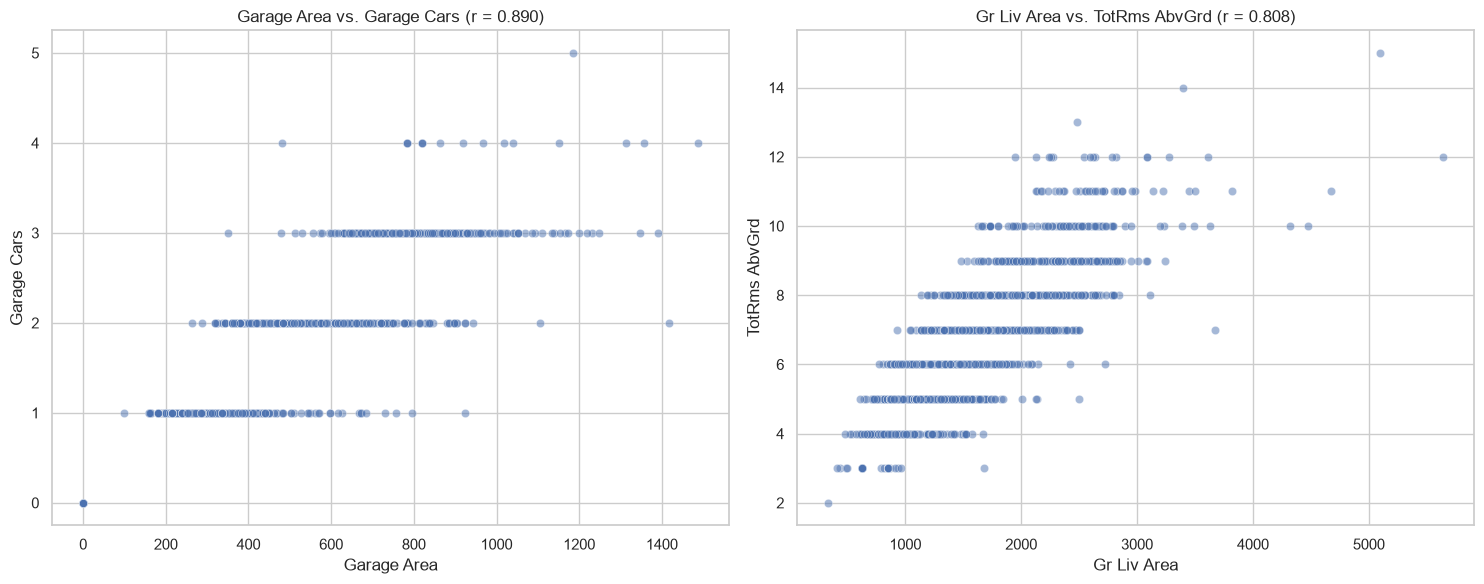

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (x, y) in zip(axes, pairs):
    r = df[x].corr(df[y])

    sns.scatterplot(
        data=df,
        x=x,
        y=y,
        alpha=0.5,
        ax=ax
    )

    ax.set_title(f"{x} vs. {y} (r = {r:.3f})")
    ax.set_xlabel(x)
    ax.set_ylabel(y)

plt.tight_layout()
plt.show()

Observatii:


În primul grafic se vede destul de clar legătura dintre `Garage Area` și `Garage Cars`. În general, cu cât garajul este mai mare, cu atât încap mai multe mașini. Punctele sunt grupate pe linii deoarece numărul de mașini poate avea doar valori întregi. Există și câteva cazuri care ies din tipar, cum ar fi garaje cu o suprafață mare, dar cu loc pentru doar 2 mașini.

O relație asemănătoare se vede și între `Gr Liv Area` și `TotRms AbvGrd`. Casele mai mari tind să aibă mai multe camere, dar aici punctele sunt ceva mai răspândite. Acest lucru poate fi explicat prin faptul că două case cu suprafețe apropiate pot avea o compartimentare diferită.

Dintre cele două perechi, relația dintre `Garage Area` și `Garage Cars` este mai puternică. Acest lucru se vede și din valorile corelației, 0.890 față de 0.808.

Posibile spurious correlations:

O corelație mare între două features nu înseamnă automat că unul îl cauzează pe celălalt.

În cazul `Garage Area` și `Garage Cars`, relația are sens deoarece un garaj mai mare are de obicei loc pentru mai multe mașini. Totuși, cele două features descriu practic două aspecte ale aceleiași caracteristici, și anume dimensiunea garajului.

Și relația dintre `Gr Liv Area` și `TotRms AbvGrd` are o explicație logică. O casă mai mare are în general mai mult spațiu pentru camere, dar numărul acestora depinde și de modul în care este împărțită casa. De aceea, aceeași suprafață poate corespunde unui număr diferit de camere.

Deci, relațiile găsite nu par să fie întâmplătoare, dar corelația singură nu este suficientă pentru a spune că există o relație directă de cauzalitate.

Regresie liniară

În continuare folosim regresia liniară pentru cele două perechi alese. Scopul este să vedem cât de bine poate fi estimată o variabilă folosind cealaltă.

Pentru fiecare pereche calculăm și valoarea R², care ne ajută să vedem cât de bine se potrivește modelul liniar datelor.

In [4]:
# Perechea 1: Garage Area -> Garage Cars

X1 = df[["Garage Area"]]
y1 = df["Garage Cars"]

model1 = LinearRegression()
model1.fit(X1, y1)

pred1 = model1.predict(X1)

r2_1 = r2_score(y1, pred1)

print(f"Coeficient: {model1.coef_[0]:.4f}")
print(f"Intercept: {model1.intercept_:.4f}")
print(f"R²: {r2_1:.3f}")

Coeficient: 0.0031
Intercept: 0.2793
R²: 0.791


Pentru prima pereche am obținut un R² de 0.791, ceea ce arată că există o legătură destul de puternică între suprafața garajului și numărul de mașini.

Coeficientul este pozitiv (0.0031), deci pe măsură ce suprafața garajului crește, modelul estimează și o creștere a numărului de mașini. Rezultatul este în concordanță cu ceea ce am observat și în scatter plot.

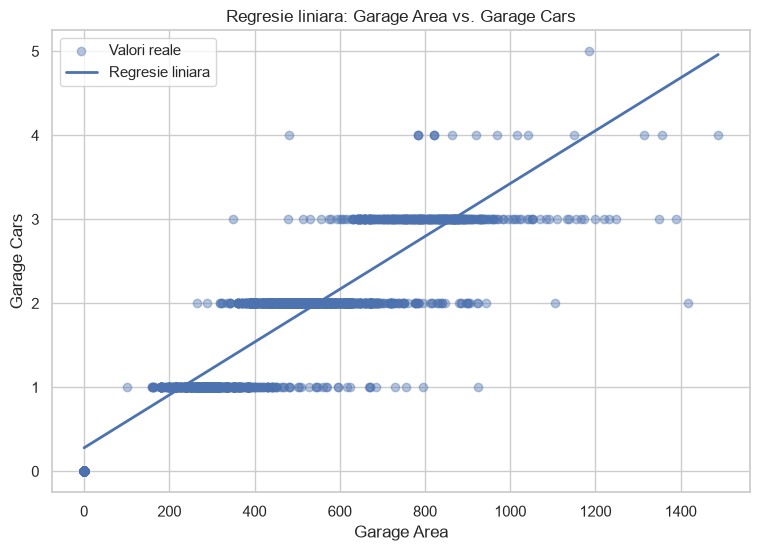

In [5]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Garage Area"],
    df["Garage Cars"],
    alpha=0.4,
    label="Valori reale"
)

order = np.argsort(df["Garage Area"].values)

plt.plot(
    df["Garage Area"].values[order],
    pred1[order],
    linewidth=2,
    label="Regresie liniara"
)

plt.xlabel("Garage Area")
plt.ylabel("Garage Cars")
plt.title("Regresie liniara: Garage Area vs. Garage Cars")
plt.legend()

plt.show()

In [6]:
# Perechea 2: Gr Liv Area -> TotRms AbvGrd

X2 = df[["Gr Liv Area"]]
y2 = df["TotRms AbvGrd"]

model2 = LinearRegression()
model2.fit(X2, y2)

pred2 = model2.predict(X2)

r2_2 = r2_score(y2, pred2)

print(f"Coeficient: {model2.coef_[0]:.4f}")
print(f"Intercept: {model2.intercept_:.4f}")
print(f"R²: {r2_2:.3f}")

Coeficient: 0.0025
Intercept: 2.6735
R²: 0.652


Pentru a doua pereche am obținut un R² de 0.652. Se vede că există o legătură destul de clară între suprafața locuibilă și numărul de camere, dar relația este mai slabă decât în cazul garajului.

Coeficientul este pozitiv (0.0025), ceea ce arată că numărul estimat de camere crește odată cu suprafața casei. Totuși, suprafața nu este suficientă pentru a determina exact numărul de camere, deoarece acesta depinde și de compartimentarea fiecărei case.

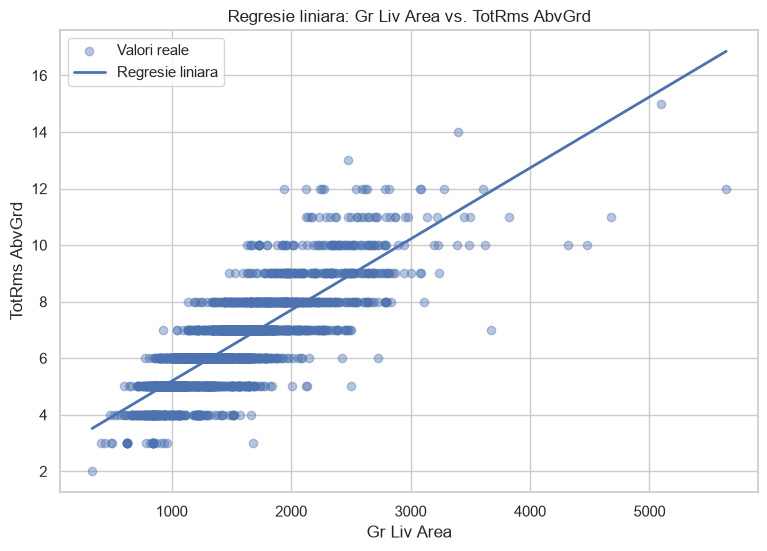

In [7]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Gr Liv Area"],
    df["TotRms AbvGrd"],
    alpha=0.4,
    label="Valori reale"
)

order = np.argsort(df["Gr Liv Area"].values)

plt.plot(
    df["Gr Liv Area"].values[order],
    pred2[order],
    linewidth=2,
    label="Regresie liniara"
)

plt.xlabel("Gr Liv Area")
plt.ylabel("TotRms AbvGrd")
plt.title("Regresie liniara: Gr Liv Area vs. TotRms AbvGrd")
plt.legend()

plt.show()

Valori reale vs. valori prezise

Pentru a vedea mai concret cum se comportă modelele, comparăm câteva valori reale din dataset cu valorile estimate prin regresia liniară.

In [8]:
sample_idx = np.linspace(0, len(df) - 1, 8, dtype=int)

comparison1 = pd.DataFrame({
    "Garage Area": df["Garage Area"].iloc[sample_idx].values,
    "Garage Cars real": y1.iloc[sample_idx].values,
    "Garage Cars prezis": pred1[sample_idx]
})

comparison1["Eroare absoluta"] = abs(
    comparison1["Garage Cars real"] -
    comparison1["Garage Cars prezis"]
)

comparison1.round(2)

,Garage Area,Garage Cars real,Garage Cars prezis,Eroare absoluta
0,528.0,2.0,1.94,0.06
1,288.0,1.0,1.19,0.19
2,440.0,1.0,1.66,0.66
3,288.0,1.0,1.19,0.19
4,511.0,2.0,1.89,0.11
5,576.0,2.0,2.09,0.09
6,440.0,2.0,1.66,0.34
7,650.0,3.0,2.32,0.68


In [9]:
comparison2 = pd.DataFrame({
    "Gr Liv Area": df["Gr Liv Area"].iloc[sample_idx].values,
    "Nr. camere real": y2.iloc[sample_idx].values,
    "Nr. camere prezis": pred2[sample_idx]
})

comparison2["Eroare absoluta"] = abs(
    comparison2["Nr. camere real"] -
    comparison2["Nr. camere prezis"]
)

comparison2.round(2)

,Gr Liv Area,Nr. camere real,Nr. camere prezis,Eroare absoluta
0,1656,7,6.84,0.16
1,892,5,4.92,0.08
2,990,5,5.16,0.16
3,1159,5,5.59,0.59
4,1337,5,6.03,1.03
5,2730,8,9.54,1.54
6,1524,4,6.50,2.50
7,2000,9,7.70,1.30


Predicții pentru valori alese

Pe lângă exemplele din dataset, putem testa modelele și pentru câteva valori alese din intervalele observate în date. Astfel putem vedea ce ar estima modelele pentru diferite dimensiuni ale garajului și ale suprafeței locuibile.

In [10]:
garage_examples = pd.DataFrame({
    "Garage Area": [300, 500, 700, 900]
})

garage_examples["Garage Cars prezis"] = model1.predict(garage_examples)

garage_examples.round(2)

,Garage Area,Garage Cars prezis
0,300,1.22
1,500,1.85
2,700,2.48
3,900,3.11


In [11]:
living_area_examples = pd.DataFrame({
    "Gr Liv Area": [1000, 1500, 2000, 2500]
})

living_area_examples["Nr. camere prezis"] = model2.predict(
    living_area_examples
)

living_area_examples.round(2)


,Gr Liv Area,Nr. camere prezis
0,1000,5.19
1,1500,6.44
2,2000,7.70
3,2500,8.96


Observații:
Pentru prima pereche, valorile prezise sunt în general destul de apropiate de cele reale. De exemplu, pentru un Garage Area de 528, valoarea reală este 2, iar modelul prezice 1.94. Există însă și cazuri cu diferente mai mari deci doar suprafața garajului nu este suficientă pentru a estima exact capacitatea acestuia.
La a doua pereche apar diferențe mai mari. Pentru un Gr Liv Area de 892, modelul prezice 4.92 camere, față de valoarea reală de 5. În schimb, la o suprafață de 1524, modelul prezice 6.50 camere, desi valoarea reală este 4. O posibilă explicație este că numărul de camere depinde și de modul în care este compartimentată casa nu doar de suprafață.
Și pentru valorile alese separat se păstrează aceeași tendință. Garajele mai mari au o capacitate estimată mai mare, iar în cazul caselor, o suprafață locuibilă mai mare duce în general la un număr estimat mai mare de camere.

## Concluzii


Dintre cele două perechi, `Garage Area` și `Garage Cars` au avut o legătură mai puternică. Corelația a fost 0.890, iar R² 0.791. La `Gr Liv Area` și `TotRms AbvGrd` am obținut valori ceva mai mici, cu o corelație de 0.808 și un R² de 0.652.

Diferența se vede si în grafice și în predicții. Pentru prima pereche, valorile prezise au fost în general mai apropiate de cele reale. La a doua pereche au apărut diferențe mai mari, deoarece suprafața unei case nu spune exact câte camere are.

În ambele cazuri relațiile au sens, dar asta nu înseamnă că un feature îl determină direct pe celălalt. Pot exista și alte caracteristici ale caselor care influențează aceste valori.